In [ ]:
import os
import numpy as np
import tensorflow as tf
from google.colab import drive
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# Mount Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Verified Shared Drive path
BASE_DIR = "/content/drive/Shareddrives/Safe Cue Project/SafeCue Dataset/mel_spectrograms_npy"

# Classes matching the Google Drive folders
CLASSES = ["Background Noise", "Fire Alarm", "Screaming", "Siren", "Smoke Alarm"]

# Forcefully crush the spectrograms down to a tiny, RAM-safe shape
IMG_SIZE = (128, 128)

def load_npy_file(file_path):
    data = np.load(file_path.numpy().decode('utf-8')).astype(np.float32)

    if data.shape != IMG_SIZE:
        data = tf.image.resize(
            np.expand_dims(data, axis=-1),
            IMG_SIZE
        ).numpy().squeeze(-1)

    # Normalize decibel values from [-80, 0] to [0, 1]
    data = np.clip(data, -80.0, 0.0)
    data = (data + 80.0) / 80.0

    data = np.expand_dims(data, axis=-1).astype(np.float32)
    return data


def load_streaming_split(split_name):
    split_dir = os.path.join(BASE_DIR, split_name)
    file_paths = []
    labels = []

    for class_idx, class_name in enumerate(CLASSES):
        class_dir = os.path.join(split_dir, class_name)
        if os.path.exists(class_dir):
            for fname in os.listdir(class_dir):
                if fname.endswith('.npy'):
                    file_paths.append(os.path.join(class_dir, fname))
                    labels.append(class_idx)

    if not file_paths:
        raise ValueError(f"No .npy files found in {split_dir}")

    # Convert to tf.data.Dataset
    path_ds = tf.data.Dataset.from_tensor_slices(file_paths)
    label_ds = tf.data.Dataset.from_tensor_slices(labels)

    # Map function to load .npy arrays wrapped with tf.py_function
    def map_fn(path, label):
        [image_tensor] = tf.py_function(load_npy_file, [path], [tf.float32])
        image_tensor.set_shape(IMG_SIZE + (1,))
        return image_tensor, label

    dataset = tf.data.Dataset.zip((path_ds, label_ds))
    if split_name == "train":
        dataset = dataset.shuffle(buffer_size=len(file_paths))

    dataset = dataset.map(map_fn, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.batch(32).prefetch(tf.data.AUTOTUNE)
    return dataset

print("\nCreating streaming datasets...")
train_ds = load_streaming_split("train")
val_ds = load_streaming_split("validation")
test_ds = load_streaming_split("test")

# The required channel dimension is configured
INPUT_SHAPE = IMG_SIZE + (1,)
print(f"Streaming ready. Model Input Shape configured to: {INPUT_SHAPE}")


Creating streaming datasets...
Streaming ready. Model Input Shape configured to: (128, 128, 1)


In [ ]:
def build_safecue_model(input_shape, num_classes=len(CLASSES)):
    model = models.Sequential([
        layers.Input(shape=input_shape),

        # Block 1
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),

        # Block 2
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),

        # Block 3
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),

        # Classification Head
        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

if 'INPUT_SHAPE' in locals():
    model = build_safecue_model(INPUT_SHAPE)
    model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,048,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,104,709 (4.21 MB)

 Trainable params: 1,104,709 (4.21 MB)

 Non-trainable params: 0 (0.00 B)


Starting memory-efficient training...
Epoch 1/30
83/83 ━━━━━━━━━━━━━━━━━━━━ 94s 1s/step - accuracy: 0.6805 - loss: 0.7523 - val_accuracy: 0.6403 - val_loss: 0.7960
Epoch 2/30
83/83 ━━━━━━━━━━━━━━━━━━━━ 91s 1s/step - accuracy: 0.7241 - loss: 0.6618 - val_accuracy: 0.6304 - val_loss: 0.8908
Epoch 3/30
83/83 ━━━━━━━━━━━━━━━━━━━━ 141s 1s/step - accuracy: 0.7442 - loss: 0.6164 - val_accuracy: 0.6304 - val_loss: 0.9646
Epoch 4/30
83/83 ━━━━━━━━━━━━━━━━━━━━ 93s 1s/step - accuracy: 0.7875 - loss: 0.5334 - val_accuracy: 0.6172 - val_loss: 1.0088
Epoch 5/30
83/83 ━━━━━━━━━━━━━━━━━━━━ 96s 1s/step - accuracy: 0.7917 - loss: 0.4945 - val_accuracy: 0.6023 - val_loss: 1.1377
Epoch 6/30
83/83 ━━━━━━━━━━━━━━━━━━━━ 139s 1s/step - accuracy: 0.8281 - loss: 0.4400 - val_accuracy: 0.5990 - val_loss: 1.1362
Epoch 7/30
83/83 ━━━━━━━━━━━━━━━━━━━━ 95s 1s/step - accuracy: 0.8395 - loss: 0.3992 - val_accuracy: 0.6155 - val_loss: 1.1112
Epoch 8/30
83/83 ━━━━━━━━━━━━━━━━━━━━ 141s 1s/step - accuracy: 0.8467 - loss:

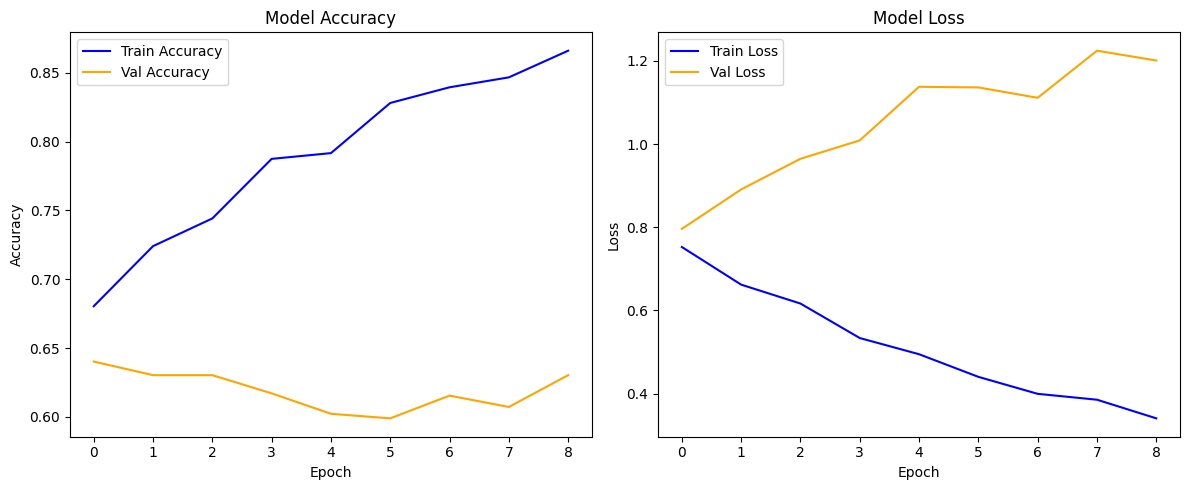

In [ ]:
# Halt training if validation loss stops improving to prevent overfitting
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=8,
    restore_best_weights=True
)

if 'train_ds' in locals():
    print("\nStarting memory-efficient training...")
    history = model.fit(
        train_ds,
        epochs=30,
        validation_data=val_ds,
        callbacks=[early_stopping]
    )

    # Plot learning curves
    plt.figure(figsize=(12, 5))

    # Accuracy Plot
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Accuracy', color='blue')
    plt.plot(history.history['val_accuracy'], label='Val Accuracy', color='orange')
    plt.title('Model Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    # Loss Plot
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss', color='blue')
    plt.plot(history.history['val_loss'], label='Val Loss', color='orange')
    plt.title('Model Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.tight_layout()
    plt.show()

In [ ]:
test_loss, test_accuracy = model.evaluate(test_ds)
print(f"Test accuracy: {test_accuracy:.2%}")

18/18 ━━━━━━━━━━━━━━━━━━━━ 100s 5s/step - accuracy: 0.0862 - loss: 1.6108
Test accuracy: 8.62%


In [ ]:

import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# Get the correct labels from the test dataset
y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

# Get the model's predictions
predictions = model.predict(test_ds)
y_pred = np.argmax(predictions, axis=1)

# Show performance for each sound class
print("CLASSIFICATION REPORT")
print(classification_report(
    y_true,
    y_pred,
    target_names=CLASSES,
    digits=3
))

print("CONFUSION MATRIX")
print(confusion_matrix(y_true, y_pred))


18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 299ms/step
CLASSIFICATION REPORT
                  precision    recall  f1-score   support

Background Noise      0.078     0.038     0.052       104
      Fire Alarm      0.000     0.000     0.000       112
       Screaming      0.046     0.027     0.034       111
           Siren      0.044     0.015     0.023       131
     Smoke Alarm      0.099     0.437     0.162        87

        accuracy                          0.086       545
       macro avg      0.054     0.104     0.054       545
    weighted avg      0.051     0.086     0.048       545

CONFUSION MATRIX
[[  4   1   2   5  92]
 [ 17   0  29  20  46]
 [  6   0   3   7  95]
 [ 17   0   0   2 112]
 [  7   0  31  11  38]]


In [ ]:
SAVE_PATH = "/content/drive/Shareddrives/Safe Cue Project/safecue_cnn_v1_latest.keras"

model.save(SAVE_PATH)

print("Model saved to:", SAVE_PATH)

Model saved to: /content/drive/Shareddrives/Safe Cue Project/safecue_cnn_v1_latest.keras


In [ ]:
model = build_safecue_model(INPUT_SHAPE)
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │     1,048,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,104,709 (4.21 MB)

 Trainable params: 1,104,709 (4.21 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "/content/drive/Shareddrives/Safe Cue Project/safecue_best.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    epochs=30,
    validation_data=val_ds,
    class_weight=class_weights,
    callbacks=[checkpoint, early_stopping]
)

NameError: name 'class_weights' is not defined

In [ ]:
import os
import hashlib
from collections import defaultdict

CLIPS_DIR = os.path.join(BASE_DIR, "one_second_clips")
audio_hashes = defaultdict(list)

for split in ["train", "validation", "test"]:
    for class_name in CLASSES:
        folder = os.path.join(CLIPS_DIR, split, class_name)

        for filename in os.listdir(folder):
            if not filename.endswith(".wav"):
                continue

            path = os.path.join(folder, filename)

            with open(path, "rb") as f:
                digest = hashlib.sha256(f.read()).hexdigest()

            audio_hashes[digest].append((split, class_name, filename))

print("=== IDENTICAL AUDIO FILES WITH DIFFERENT LABELS ===")
count = 0

for digest, entries in audio_hashes.items():
    labels = {entry[1] for entry in entries}

    if len(labels) > 1:
        count += 1
        print(f"\nDuplicate group {count}:")
        for split, label, filename in entries:
            print(f"  {split:10} | {label:15} | {filename}")

print(f"\nTotal identical-audio groups with conflicting labels: {count}")


DUPLICATE ACROSS SPLITS:
  train      | Background Noise | 5fyzKTSL20w_110.000_120.000 (1)_0000.wav
  test       | Background Noise | 5fyzKTSL20w_110.000_120.000_0000.wav

DUPLICATE ACROSS SPLITS:
  train      | Background Noise | 5fyzKTSL20w_110.000_120.000 (1)_0001.wav
  test       | Background Noise | 5fyzKTSL20w_110.000_120.000_0001.wav

DUPLICATE ACROSS SPLITS:
  train      | Background Noise | 5fyzKTSL20w_110.000_120.000 (1)_0002.wav
  test       | Background Noise | 5fyzKTSL20w_110.000_120.000_0002.wav

DUPLICATE ACROSS SPLITS:
  train      | Background Noise | 5fyzKTSL20w_110.000_120.000 (1)_0003.wav
  test       | Background Noise | 5fyzKTSL20w_110.000_120.000_0003.wav

DUPLICATE ACROSS SPLITS:
  train      | Background Noise | 5fyzKTSL20w_110.000_120.000 (1)_0004.wav
  test       | Background Noise | 5fyzKTSL20w_110.000_120.000_0004.wav

DUPLICATE ACROSS SPLITS:
  train      | Background Noise | 5fyzKTSL20w_110.000_120.000 (1)_0005.wav
  test       | Background Noise | 5fyzK


Evaluating on unseen test set...

Final Test Accuracy: 53.94%

Classification Report:
                  precision    recall  f1-score   support

Background Noise       0.52      0.88      0.65       104
      Fire Alarm       0.39      0.19      0.25       112
       Screaming       0.42      0.15      0.23       111
           Siren       0.82      0.95      0.88       131
     Smoke Alarm       0.33      0.46      0.38        87

        accuracy                           0.54       545
       macro avg       0.50      0.53      0.48       545
    weighted avg       0.51      0.54      0.49       545



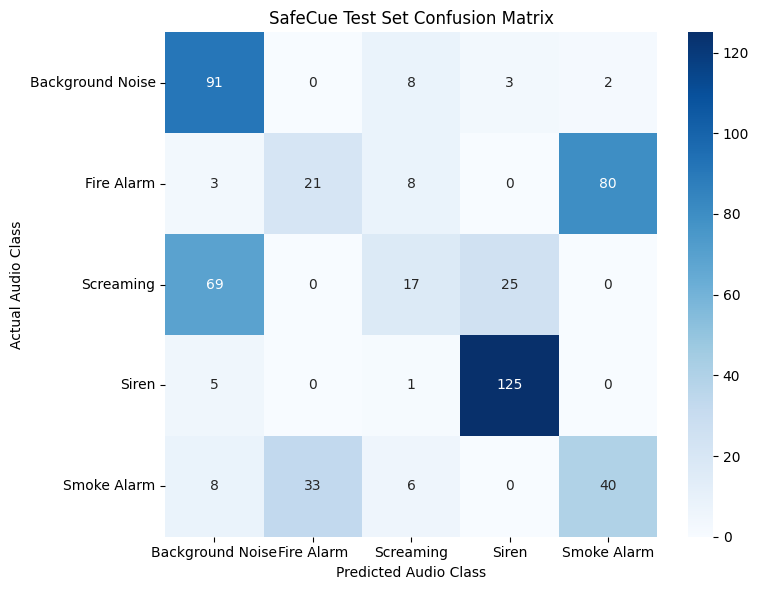


Model saved to Shared Drive as safecue_cnn_v1.h5


In [ ]:

if 'test_ds' in locals():
    print("\nEvaluating on unseen test set...")

    test_loss, test_acc = model.evaluate(test_ds, verbose=0)
    print(f"\nFinal Test Accuracy: {test_acc * 100:.2f}%\n")

    # Collect predictions and true labels together, batch by batch
    y_true = []
    y_pred = []

    for x_batch, y_batch in test_ds:
        probs = model.predict(x_batch, verbose=0)
        y_pred.extend(np.argmax(probs, axis=1))
        y_true.extend(y_batch.numpy())

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    print("Classification Report:")
    print(classification_report(
        y_true,
        y_pred,
        labels=np.arange(len(CLASSES)),
        target_names=CLASSES,
        zero_division=0
    ))

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=np.arange(len(CLASSES))
    )

    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues',
        xticklabels=CLASSES, yticklabels=CLASSES
    )
    plt.ylabel('Actual Audio Class')
    plt.xlabel('Predicted Audio Class')
    plt.title('SafeCue Test Set Confusion Matrix')
    plt.tight_layout()
    plt.show()

    model.save(
        '/content/drive/Shareddrives/Safe Cue Project/safecue_cnn_v1.h5'
    )
    print("\nModel saved to Shared Drive as safecue_cnn_v1.h5")


In [ ]:
import tensorflow as tf

# Convert the trained Keras model to TensorFlow Lite
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

# Save the converted model
output_path = "/content/drive/Shareddrives/Safe Cue Project/safecue_cnn_v1.tflite"

with open(output_path, "wb") as f:
    f.write(tflite_model)

print("TensorFlow Lite model saved to:", output_path)
print("Model size:", round(len(tflite_model) / 1024, 2), "KB")

In [ ]:
print(CLASSES)

['Background Noise', 'Fire Alarm', 'Screaming', 'Siren', 'Smoke Alarm']


In [ ]:
from google.colab import files

files.download(
    "/content/drive/Shareddrives/Safe Cue Project/safecue_cnn_v1.tflite"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import numpy as np
import tensorflow as tf

BASE_DIR = "/content/drive/Shareddrives/Safe Cue Project/SafeCue Dataset/mel_spectrograms_npy"

CLASSES = [
    "Background Noise",
    "Fire Alarm",
    "Screaming",
    "Siren",
    "Smoke Alarm"
]

# Choose one real example from the Fire Alarm class
class_dir = os.path.join(BASE_DIR, "test", "Fire Alarm")
files = sorted(
    f for f in os.listdir(class_dir)
    if f.endswith(".npy")
)

print("Fire Alarm test examples:", len(files))

if not files:
    raise ValueError("No .npy files found in the Fire Alarm test folder.")

# Load one real spectrogram
file_path = os.path.join(class_dir, files[0])
data = np.load(file_path).astype(np.float32)

# Match your model's original preprocessing exactly
if data.shape != (128, 128):
    data = tf.image.resize(
        np.expand_dims(data, axis=-1),
        (128, 128)
    ).numpy().squeeze(-1)

if data.max() > 1.0:
    data = data / 255.0

data = np.expand_dims(data, axis=-1).astype(np.float32)

# Add batch dimension and save for the UNO Q
sample = np.expand_dims(data, axis=0)
output_path = "/content/safecue_test_sample.npy"
np.save(output_path, sample)

print("Selected file:", files[0])
print("Saved sample shape:", sample.shape)
print("Data range:", float(sample.min()), "to", float(sample.max()))
print("Saved to:", output_path)

Fire Alarm test examples: 112
Selected file: -wMFgnGcIms_100.000_110.000_0000.npy
Saved sample shape: (1, 128, 128, 1)
Data range: -80.0 to -0.2395227551460266
Saved to: /content/safecue_test_sample.npy


In [ ]:

import os
import numpy as np
import tensorflow as tf

BASE_DIR = "/content/drive/Shareddrives/Safe Cue Project/SafeCue Dataset/mel_spectrograms_npy"

CLASSES = [
    "Background Noise",
    "Fire Alarm",
    "Screaming",
    "Siren",
    "Smoke Alarm"
]

X_test = []
y_test = []
counts = {}

for class_idx, class_name in enumerate(CLASSES):
    class_dir = os.path.join(BASE_DIR, "test", class_name)

    files = sorted(
        f for f in os.listdir(class_dir)
        if f.endswith(".npy")
    )

    counts[class_name] = len(files)

    for filename in files:
        file_path = os.path.join(class_dir, filename)
        data = np.load(file_path).astype(np.float32)

        # Match the preprocessing used during training
        if data.shape != (128, 128):
            data = tf.image.resize(
                np.expand_dims(data, axis=-1),
                (128, 128)
            ).numpy().squeeze(-1)

        if data.max() > 1.0:
            data = data / 255.0

        data = np.expand_dims(data, axis=-1).astype(np.float32)

        X_test.append(data)
        y_test.append(class_idx)

X_test = np.stack(X_test).astype(np.float32)
y_test = np.array(y_test, dtype=np.int64)

output_path = "/content/safecue_full_test.npz"
np.savez_compressed(
    output_path,
    X_test=X_test,
    y_test=y_test
)

print("\nExamples per class:")
for name, count in counts.items():
    print(f"{name}: {count}")

print("\nTotal test examples:", len(y_test))
print("Input array shape:", X_test.shape)
print("Labels shape:", y_test.shape)
print("Saved file:", output_path)
print(f"File size: {os.path.getsize(output_path) / (1024*1024):.2f} MB")



Examples per class:
Background Noise: 104
Fire Alarm: 112
Screaming: 111
Siren: 131
Smoke Alarm: 87

Total test examples: 545
Input array shape: (545, 128, 128, 1)
Labels shape: (545,)
Saved file: /content/safecue_full_test.npz
File size: 27.33 MB


In [ ]:

import os
import numpy as np

BASE_DIR = "/content/drive/Shareddrives/Safe Cue Project/SafeCue Dataset/mel_spectrograms_npy"
CLASSES = ["Background Noise", "Fire Alarm", "Screaming", "Siren", "Smoke Alarm"]

for class_name in CLASSES:
    class_dir = os.path.join(BASE_DIR, "train", class_name)
    files = sorted(
        f for f in os.listdir(class_dir) if f.endswith(".npy")
    )

    print(f"\n{class_name}")

    for filename in files[:3]:
        data = np.load(os.path.join(class_dir, filename))
        print(
            f"{filename}: shape={data.shape}, "
            f"min={data.min():.2f}, max={data.max():.2f}, "
            f"mean={data.mean():.2f}, std={data.std():.2f}"
        )



Background Noise
-RRi3QktLdc_500.000_510.000_0000.npy: shape=(64, 32), min=-80.00, max=0.00, mean=-67.32, std=18.31
-RRi3QktLdc_500.000_510.000_0001.npy: shape=(64, 32), min=-77.05, max=0.00, mean=-34.26, std=11.22
-RRi3QktLdc_500.000_510.000_0002.npy: shape=(64, 32), min=-67.67, max=0.00, mean=-34.17, std=11.00

Fire Alarm
-a9xYse4q-Y_70.000_80.000_0000.npy: shape=(64, 32), min=-48.57, max=0.00, mean=-22.76, std=11.12
-a9xYse4q-Y_70.000_80.000_0001.npy: shape=(64, 32), min=-61.39, max=0.00, mean=-36.61, std=14.21
-a9xYse4q-Y_70.000_80.000_0002.npy: shape=(64, 32), min=-80.00, max=0.00, mean=-46.05, std=15.28

Screaming
0YnOMAls83g_30.000_40.000_0000.npy: shape=(64, 32), min=-70.99, max=0.00, mean=-26.11, std=12.09
0YnOMAls83g_30.000_40.000_0001.npy: shape=(64, 32), min=-72.38, max=0.00, mean=-26.39, std=13.39
0YnOMAls83g_30.000_40.000_0002.npy: shape=(64, 32), min=-72.91, max=0.00, mean=-33.24, std=13.25

Siren
-_u5wrx8Ffo_30.000_40.000_0000.npy: shape=(64, 32), min=-64.69, max=0.00,

In [ ]:

import os

folder = "/content/drive/Shareddrives/Safe Cue Project/SafeCue Dataset/one_second_clips"

print("Does folder exist?", os.path.exists(folder))

if os.path.exists(folder):
    print("Folders inside:")
    print(os.listdir(folder))
else:
    print("Google Drive may need to be mounted.")


Does folder exist? True
Folders inside:
['train', 'validation', 'test']


In [ ]:

import os
import hashlib
from collections import defaultdict

base = "/content/drive/Shareddrives/Safe Cue Project/SafeCue Dataset/one_second_clips"
classes = ["Background Noise", "Fire Alarm", "Screaming", "Siren", "Smoke Alarm"]

audio_hashes = defaultdict(list)

for split in ["train", "validation", "test"]:
    for label in classes:
        folder = os.path.join(base, split, label)

        if not os.path.isdir(folder):
            continue

        for filename in os.listdir(folder):
            if not filename.lower().endswith(".wav"):
                continue

            path = os.path.join(folder, filename)

            with open(path, "rb") as f:
                digest = hashlib.sha256(f.read()).hexdigest()

            audio_hashes[digest].append((split, label, filename))

conflicts = [
    entries for entries in audio_hashes.values()
    if len({entry[1] for entry in entries}) > 1
]

leaks = [
    entries for entries in audio_hashes.values()
    if len({entry[0] for entry in entries}) > 1
]

print("Unique audio files:", len(audio_hashes))
print("Identical audio with conflicting labels:", len(conflicts))
print("Identical audio across multiple splits:", len(leaks))

print("\nFirst 5 conflicting examples:")
for entries in conflicts[:5]:
    for split, label, filename in entries:
        print(f"  {split} | {label} | {filename}")
    print()


Unique audio files: 3572
Identical audio with conflicting labels: 102
Identical audio across multiple splits: 67

First 5 conflicting examples:
  train | Background Noise | 19DRe0cdeXQ_20.000_30.000 (1)_0000.wav
  train | Background Noise | 19DRe0cdeXQ_20.000_30.000 (1)_0004.wav
  train | Background Noise | 19DRe0cdeXQ_20.000_30.000 (1)_0005.wav
  train | Background Noise | 19DRe0cdeXQ_20.000_30.000 (1)_0006.wav
  train | Background Noise | 19DRe0cdeXQ_20.000_30.000 (1)_0007.wav
  train | Background Noise | 19DRe0cdeXQ_20.000_30.000 (1)_0008.wav
  train | Background Noise | 19DRe0cdeXQ_20.000_30.000 (1)_0009.wav
  train | Background Noise | 19DRe0cdeXQ_20.000_30.000 (1)_0010.wav
  train | Background Noise | 19DRe0cdeXQ_20.000_30.000_0000.wav
  train | Background Noise | 19DRe0cdeXQ_20.000_30.000_0004.wav
  train | Background Noise | 19DRe0cdeXQ_20.000_30.000_0005.wav
  train | Background Noise | 19DRe0cdeXQ_20.000_30.000_0006.wav
  train | Background Noise | 19DRe0cdeXQ_20.000_30.000_0

In [ ]:
import os
import hashlib
import random
import shutil
from collections import defaultdict

# --- CONFIGURATION ---
# Point this to the folder containing your RAW, unsliced audio.
# It should have 5 subfolders (Fire Alarm, Smoke Alarm, etc.)
RAW_BASE_DIR = "/content/drive/Shareddrives/Safe Cue Project/raw_clips"
CLEAN_SPLIT_DIR = "/content/drive/Shareddrives/Safe Cue Project/clean_split_clips"

CLASSES = ["Background Noise", "Fire Alarm", "Screaming", "Siren", "Smoke Alarm"]

def get_file_hash(filepath):
    """Returns the SHA256 hash of a file to find exact duplicates."""
    hasher = hashlib.sha256()
    with open(filepath, 'rb') as afile:
        buf = afile.read()
        hasher.update(buf)
    return hasher.hexdigest()

print("--- PHASE 1: IDENTIFYING & PURGING CONFLICTS ---")
file_hashes = defaultdict(list)

# 1. Map every file to its hash
for class_name in CLASSES:
    class_dir = os.path.join(RAW_BASE_DIR, class_name)
    if not os.path.exists(class_dir):
        continue

    for filename in os.listdir(class_dir):
        if filename.endswith(".wav"):
            filepath = os.path.join(class_dir, filename)
            file_hash = get_file_hash(filepath)
            file_hashes[file_hash].append((class_name, filepath))

valid_files = {c: [] for c in CLASSES}
conflict_count = 0

# 2. Filter out the conflicts
for file_hash, occurrences in file_hashes.items():
    labels = set([item[0] for item in occurrences])

    if len(labels) > 1:
        # CONFLICT: The exact same audio file is in multiple classes.
        # Action: Drop it entirely. It is tainted data.
        conflict_count += 1
    else:
        # VALID: Keep only the first instance to remove any same-class duplicates
        class_name, filepath = occurrences[0]
        valid_files[class_name].append(filepath)

print(f"Purged {conflict_count} cross-class conflicts.")

print("\n--- PHASE 2: 70/15/15 SPLITTING ---")
# Create the target directories
for split in ["train", "validation", "test"]:
    for class_name in CLASSES:
        os.makedirs(os.path.join(CLEAN_SPLIT_DIR, split, class_name), exist_ok=True)

# Shuffle and split
for class_name in CLASSES:
    files = valid_files[class_name]
    random.shuffle(files)

    total = len(files)
    train_end = int(total * 0.7)
    val_end = int(total * 0.85)

    train_files = files[:train_end]
    val_files = files[train_end:val_end]
    test_files = files[val_end:]

    splits = {
        "train": train_files,
        "validation": val_files,
        "test": test_files
    }

    for split_name, split_list in splits.items():
        for filepath in split_list:
            filename = os.path.basename(filepath)
            dest = os.path.join(CLEAN_SPLIT_DIR, split_name, class_name, filename)
            shutil.copy2(filepath, dest)

    print(f"{class_name}: {len(train_files)} train | {len(val_files)} val | {len(test_files)} test")

print("\nDone! Your raw files are now conflict-free and safely split.")

--- PHASE 1: IDENTIFYING & PURGING CONFLICTS ---
Purged 0 cross-class conflicts.

--- PHASE 2: 70/15/15 SPLITTING ---
Background Noise: 0 train | 0 val | 0 test
Fire Alarm: 0 train | 0 val | 0 test
Screaming: 0 train | 0 val | 0 test
Siren: 0 train | 0 val | 0 test
Smoke Alarm: 0 train | 0 val | 0 test

Done! Your raw files are now conflict-free and safely split.
